# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?


**Análisis**

***Users***

**City:** Se encontraron 469 registros nulos, equivalentes al 11,72% del dataset.
**Acción recomendada:**
- Conservar la columna y evaluar si los valores faltantes siguen un patrón. Dependiendo de los resultados, se puede imputar con la ciudad más frecuente, usar un valor genérico (“Unknown”) o analizar si la ausencia aporta información sobre el comportamiento del cliente.

**Churn Date:** Presenta 3534 valores nulos, lo que corresponde al 88,35% de los registros.
**Acción recomendada:**
- Dado que la mayoría de los clientes aún no han abandonado el servicio, esta columna no aporta valor en el análisis actual y puede excluirse del proceso de preparación.

***Usage***

**Date:** Se identificaron 50 registros nulos (0,125%).
**Acción recomendada:**
- El porcentaje es mínimo, por lo que estos registros pueden ignorarse sin afectar la calidad del análisis.

**Duration:** Tiene 22.076 valores faltantes, equivalentes al 55,19% del dataset.
**Length:** Registra 17.896 valores nulos, correspondientes al 44,74%.

**Acción recomendada:**
- Ambas variables son críticas para responder las preguntas de negocio (tiempo de llamadas y cantidad de mensajes). Por ello, se recomienda aplicar técnicas de imputación que permitan conservar la mayor cantidad de información posible y garantizar la consistencia de los resultados.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
user_numeric_cols = users.select_dtypes(include="number")
user_numeric_cols.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- **`user_id`:** Los valores se encuentran dentro de un rango consistente (10.000 a 13.999), sin presencia de nulos ni valores fuera de lo esperado. Esto indica que la columna puede utilizarse directamente como identificador único de los registros, sin necesidad de limpieza adicional.
- **`age`:** Aunque la mayoría de los valores se distribuyen en un rango lógico (32 a 79 años), se detecta un valor mínimo de -999, que corresponde a un sentinel o marcador de dato faltante/erróneo. Este valor distorsiona las estadísticas, elevando artificialmente la desviación estándar y afectando la interpretación de la distribución.
**Por ello, es necesario aplicar un proceso de limpieza que:**

- Identifique y reemplace los valores sentinela por nulos.
- Evalúe la imputación de edades faltantes (por ejemplo, con la mediana) o la eliminación de registros, según el objetivo del análisis.
- Verifique si existen otros valores fuera de rango que también deban corregirse.

In [13]:
# explorar columnas numéricas de usage
usage_numeric_cols = usage.select_dtypes(include="number")
usage_numeric_cols.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


Las columnas `id` y `user_id`Ambas muestran rangos consistentes y completos (sin nulos ni valores fuera de lo esperado). Se pueden usar directamente como identificadores sin necesidad de limpieza adicional.
<br>
Las columnas `duration` y `length` muestran aspectos que llaman la atención:
 1. Los conteos son menores que el total de registros (17.924 y 22.104 frente a 40.000), lo que confirma la existencia de valores faltantes.
 2. Se observan valores mínimos de 0, que pueden ser legítimos (llamadas o mensajes sin duración/longitud) pero también podrían reflejar registros incompletos.
 3. Los valores máximos son muy altos (120 en duration y 1490 en length), lo que sugiere posibles outliers que deben revisarse para confirmar si son casos reales o errores de captura.
 4. La desviación estándar es elevada en ambas columnas, lo que indica una dispersión considerable y refuerza la necesidad de analizar la distribución.


In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


`city`:
- Se registran 3531 valores válidos, lo que confirma la existencia de 469 nulos (11,7%), tal como habías identificado antes.
- Hay 7 ciudades únicas, siendo Bogotá la más frecuente con 808 registros.

Esto sugiere que la columna es relevante para segmentar por ubicación, pero requiere limpieza o imputación de los valores faltantes para no perder representatividad.

---

`plan`:
- Se tienen 4000 registros completos, sin valores nulos.
- Solo hay 2 categorías únicas: Básico y Premium.
- El plan Básico es el más frecuente, con 2595 usuarios (≈65%).

Esto indica una clara preferencia por el plan de entrada, lo que puede ser un hallazgo importante para el área comercial.

In [15]:
# explorar columna categórica de usage
columnas_usage = ['type']
usage[columnas_usage].describe()

,type
count,40000
unique,2
top,text
freq,22092


`type`:
La columna tiene 40.000 entradas válidas, lo que indica que no hay valores nulos.

Solo existen 2 valores únicos, lo que simplifica la segmentación, el valor más frecuente es “text”, con 22.092 registros (≈55%). Esto muestra un claro predominio de un tipo de uso sobre el otro.

El predominio de “text” puede reflejar que la mayoría de los usuarios utilizan más mensajes que llamadas, lo cual es un hallazgo relevante para entender patrones de comportamiento.

## 📊 Diagnóstico de valores inválidos y sentinels (Sección 2.2)

### Columnas numéricas
| Columna   | Problema detectado | Acción recomendada |
|-----------|--------------------|--------------------|
| ***age***      | Valor sentinel (-999) y posible rango inválido | Reemplazar por nulos y aplicar imputación (ej. mediana) |
| ***duration***  | Alto porcentaje de nulos y outliers (máx. 120) | Imputar valores faltantes y validar outliers |
| ***length***    | Alto porcentaje de nulos y outliers (máx. 1490) | Imputar valores faltantes y revisar si los ceros son legítimos |

### Columnas categóricas
| Columna   | Problema detectado | Acción recomendada |
|-----------|--------------------|--------------------|
| ***city***      | 469 valores nulos (≈11,7%) | Imputar con categoría más frecuente o “Unknown” |
| ***plan***      | Sin problemas, datos completos | Lista para análisis |
| ***type***      | Sin problemas, 2 categorías, predominio de “text” | Lista para análisis |

---

✅ **Conclusión general:**  
Los valores inválidos se concentran en *age* (sentinels) y en las columnas de uso (*duration*, *length*) por nulos y outliers. La columna *city* también requiere limpieza por valores faltantes. En contraste, *user_id*, *id*, *plan* y *type* están limpias y listas para usarse directamente.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce', utc = True)

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce', utc = True)

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`:
- Los años 2022, 2023 y 2024 aparecen con cantidades similares de registros (alrededor de 1300 cada uno), lo cual es consistente con la premisa de que los datos llegan hasta 2024.

- Sin embargo, hay 40 registros con año 2026, lo que constituye una fecha imposible según la regla de negocio (no deberían existir datos posteriores a 2024).

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date`:
- La columna date del DataFrame usage muestra que todos los registros corresponden al año 2024, con un total de 39,950 entradas.

- No aparecen años fuera de rango ni inconsistencias como en el caso de reg_date de users.

- Estan los 50 valores faltantes que se vieron en secciones anteriores que segun el registro de datos se podrian igualar al mismo año

- Esto sugiere que los datos de uso están concentrados únicamente en el último año disponible, lo cual puede ser lógico si el sistema solo comenzó a registrar actividad en 2024 o si el dataset fue filtrado para ese periodo.

## 📊 Diagnóstico de fechas fuera de rango (Sección 2.3)

| Dataset | Problema detectado | Acción recomendada |
|---------|--------------------|--------------------|
| **users (`reg_date`)** | Registros válidos en 2022, 2023 y 2024. Sin embargo, aparecen 40 registros en 2026, lo cual excede el rango permitido (datos solo hasta 2024). | Marcar como inválidos. Revisar si son errores de digitación (ej. 2026 → 2024). Si no se puede corregir, eliminar los registros. Documentar la regla de validación en el proceso ETL. |
| **usage (`date`)** | Todos los registros corresponden al año 2024 (39,950 entradas). No se detectan fechas imposibles. | Mantener los registros faltantes sobre el mismo año. se restringe el análisis a un único año. Solicitar datos de años anteriores si se requiere análisis histórico. |

---

✅ **Conclusión general:**  
- El dataset `users` requiere limpieza por fechas imposibles (2026).  
- El dataset `usage` está consistente, pero limitado a un único año (2024).  
- Se recomienda aplicar reglas de validación de fechas en la etapa de ETL para prevenir errores futuros.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median() #calcular la mediana excluyendo los sentinels
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()
users['city'].head()

0    Medellín
1        <NA>
2        CDMX
3      Bogotá
4         GDL
Name: city, dtype: object

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts()

2024.0    1330
2023.0    1316
2022.0    1314
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

## 📊 Diagnóstico de nulos en `usage` (Sección 3.2)

| Columna   | Problema detectado | Acción recomendada |
|-----------|--------------------|--------------------|
| **duration** | Los nulos se concentran en registros de tipo *text*. La variable solo aplica a llamadas. | Mantener los nulos. Justificar que son esperados porque *duration* no aplica a mensajes de texto. |
| **length**   | Los nulos se concentran en registros de tipo *call*. La variable solo aplica a mensajes de texto. | Mantener los nulos. Justificar que son esperados porque *length* no aplica a llamadas. |

---

✅ **Conclusión general:**  
Los nulos en *duration* y *length* son **MAR (Missing At Random)** condicionados por la columna *type*. No representan errores de captura, sino la lógica del negocio: cada variable aplica únicamente a un tipo de evento.  
Por tanto, deben conservarse como nulos y documentarse como parte del diseño del dataset.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")
    .agg(
        cant_mensajes=("is_text", "sum"),
        cant_llamadas=("is_call", "sum"),
        cant_minutos_llamada=("duration", "sum")
    )
    .reset_index()
)

# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [27]:
# Resumen estadístico de las columnas numéricas
profiles_numeric_cols = user_profile.select_dtypes(include="number") # Selecciona solo las columnas numéricas relevantes
profiles_numeric_cols.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [28]:
# Distribución porcentual del tipo de plan
plan_distribution = (
    users["plan"]
    .value_counts(normalize=True) * 100
).round(2)

print("\n📈 Distribución de planes (%):")
print(plan_distribution)


📈 Distribución de planes (%):
Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

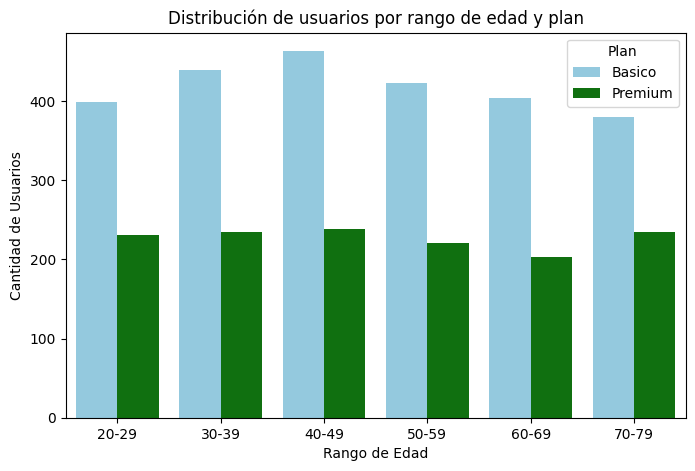

In [29]:
# Histograma para visualizar la edad (age)
# Definir los rangos de edad
bins_edades = [20, 30, 40, 50, 60, 70, 80]
labels_edades = ["20-29", "30-39", "40-49", "50-59", "60-69", "70-79"]

# Crear una nueva columna con el rango de edad
user_profile["age_group"] = pd.cut(user_profile["age"], bins=bins_edades, labels=labels_edades, right=False)

# Graficar barras por rango de edad y plan
plt.figure(figsize=(8,5))
sns.countplot(
    data=user_profile,
    x="age_group",
    hue="plan",
    palette=["skyblue","green"]
)

plt.title("Distribución de usuarios por rango de edad y plan")
plt.xlabel("Rango de Edad")
plt.ylabel("Cantidad de Usuarios")
plt.legend(title="Plan")
plt.show()

💡Insights: 
- **Dominio del plan Básico en todos los rangos:** en cada intervalo, el plan Básico supera al Premium en número de usuarios. Esto confirma que la oferta de entrada es la más popular y accesible.
- **Pico en 40–49 años:** el rango con mayor cantidad de usuarios es 40–49, especialmente en el plan Básico. Este grupo parece ser el núcleo de la base de clientes.
- **Premium más competitivo en 30–49:** aunque sigue siendo menor, el Premium logra su mejor participación relativa en estos rangos, lo que sugiere que aquí hay más disposición a pagar por beneficios adicionales.
- **Descenso progresivo en mayores de 50:** tanto Básico como Premium caen en volumen en los rangos 60–69 y 70–79, lo que indica menor adopción en adultos mayores.

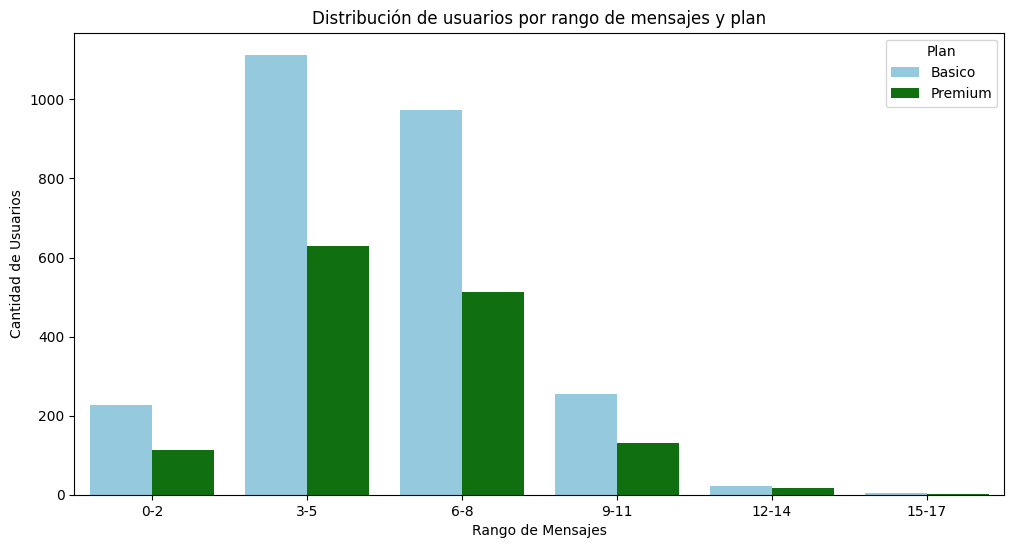

In [30]:
# Histograma para visualizar la cant_mensajes

# Definir los rangos automáticamente de 3 en 3 hasta el máximo
max_msgs = user_profile["cant_mensajes"].max()
bins_mensajes = np.arange(0, max_msgs+3, 3)   # intervalos de 3
labels_mensajes = [f"{int(i)}-{int(i+2)}" for i in bins_mensajes[:-1]]

# Crear una nueva columna con el rango de mensajes
user_profile["msg_group"] = pd.cut(
    user_profile["cant_mensajes"],
    bins=bins_mensajes,
    labels=labels_mensajes,
    right=False
)

# Graficar barras por rango de mensajes y plan
plt.figure(figsize=(12,6))
sns.countplot(
    data=user_profile,
    x="msg_group",
    hue="plan",
    palette=["skyblue","green"]
)

plt.title("Distribución de usuarios por rango de mensajes y plan")
plt.xlabel("Rango de Mensajes")
plt.ylabel("Cantidad de Usuarios")
plt.legend(title="Plan")
plt.show()

💡Insights: 
- **Concentración en rangos bajos (3–8 mensajes):** la mayoría de usuarios, tanto Básico como Premium, se concentran en enviar entre 3 y 8 mensajes. Esto indica que el uso típico es moderado.
- **Muy pocos heavy users (12+ mensajes):** la cantidad de usuarios que envían más de 12 mensajes cae drásticamente. Esto muestra que el uso intensivo es raro y está concentrado en un grupo pequeño.
- **Distribusion igual en envio de mensajes entre premium y basico:** Aunque sigue viendose mas movimiento de mensajes en los planes basicos esto es por la cantidad de usuarios, pero en su distribusion hay un movimiento parejo donde ninguno de los dos tipos de usuarios usa mayormente este servicio

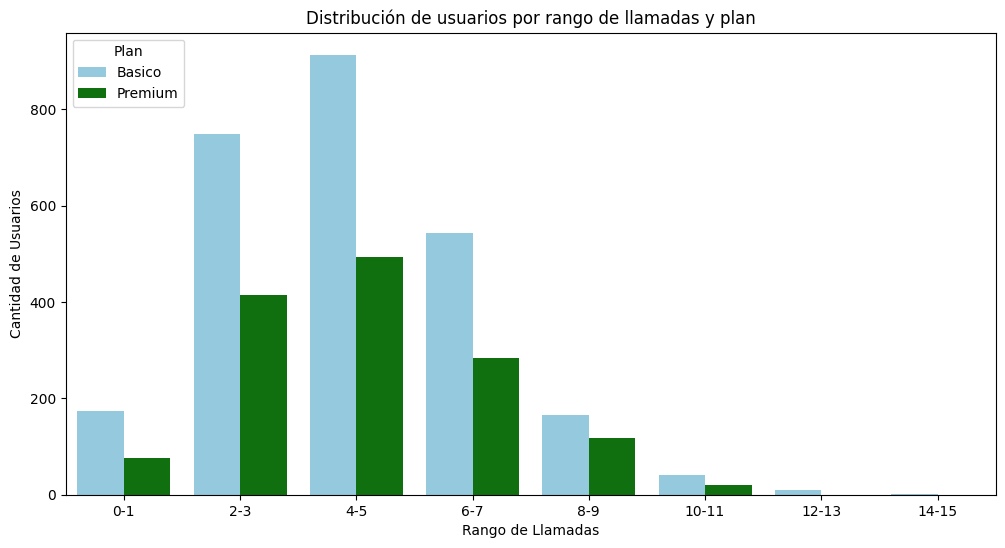

In [31]:
# Histograma para visualizar la cant_llamadas

# Definir los rangos automáticamente de 2 en 2 llamadas hasta el máximo
max_llamadas = user_profile["cant_llamadas"].max()
bins_llamadas = np.arange(0, max_llamadas+2, 2)   # intervalos de 2 llamadas
labels_llamadas = [f"{int(i)}-{int(i+1)}" for i in bins_llamadas[:-1]]

# Crear columna con rango de llamadas
user_profile["call_count_group"] = pd.cut(
    user_profile["cant_llamadas"],
    bins=bins_llamadas,
    labels=labels_llamadas,
    right=False
)

# Graficar barras por rango de llamadas y plan
plt.figure(figsize=(12,6))
sns.countplot(
    data=user_profile,
    x="call_count_group",
    hue="plan",
    palette=["skyblue","green"]
)

plt.title("Distribución de usuarios por rango de llamadas y plan")
plt.xlabel("Rango de Llamadas")
plt.ylabel("Cantidad de Usuarios")
plt.legend(title="Plan")
plt.show()

💡Insights: 
- **Mayor concentración en rangos bajos (2–5 llamadas):** la mayoría de usuarios se ubica en los intervalos de pocas llamadas. Esto indica que el comportamiento típico es de uso moderado, no intensivo.
- **Premium sigue la misma tendencia:** aunque con menor volumen, los usuarios Premium muestran un patrón similar: más presentes en rangos bajos y decreciendo conforme aumenta el número de llamadas.
- **Caída progresiva en rangos altos (10+ llamadas):** muy pocos usuarios realizan un número elevado de llamadas, lo que muestra que el servicio se usa principalmente para comunicación puntual.

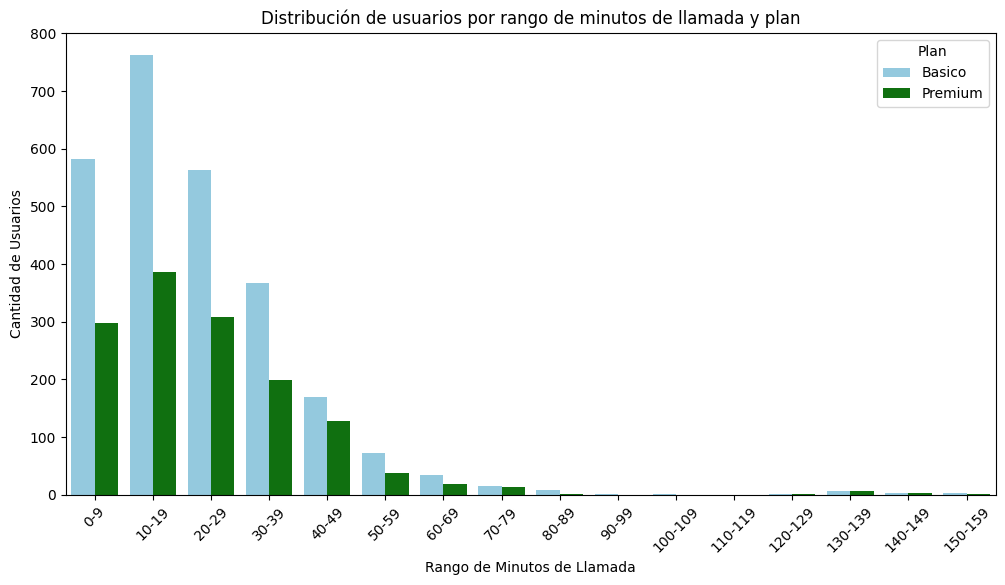

In [32]:
# Histograma para visualizar la cant_minutos_llamada

# Definir los rangos automáticamente de 10 en 10 minutos hasta el máximo
max_minutos = user_profile["cant_minutos_llamada"].max()
bins_minutos = np.arange(0, max_minutos+10, 10)   # intervalos de 10 minutos
labels_minutos = [f"{int(i)}-{int(i+9)}" for i in bins_minutos[:-1]]

# Crear columna con rango de minutos de llamada
user_profile["call_group"] = pd.cut(
    user_profile["cant_minutos_llamada"],
    bins=bins_minutos,
    labels=labels_minutos,
    right=False
)

# Graficar barras por rango de minutos y plan
plt.figure(figsize=(12,6))
sns.countplot(
    data=user_profile,
    x="call_group",
    hue="plan",
    palette=["skyblue","green"]
)

plt.title("Distribución de usuarios por rango de minutos de llamada y plan")
plt.xlabel("Rango de Minutos de Llamada")
plt.ylabel("Cantidad de Usuarios")
plt.legend(title="Plan")
plt.xticks(rotation=45)   # rotar etiquetas para que no se encimen
plt.show()

💡Insights: 
- **Alta concentración en llamadas cortas (0–19 minutos):** la mayoría de usuarios, tanto Básico como Premium, se concentran en rangos bajos de duración. Esto indica que el uso típico del servicio es de llamadas breves.
- **Premium mantiene presencia estable pero menor:** aunque siempre por debajo, el Premium conserva usuarios en todos los rangos, lo que sugiere que sus clientes tienen hábitos similares pero con menor volumen total.
- **Caída progresiva en llamadas largas (60+ minutos):** muy pocos usuarios realizan llamadas extensas, lo que muestra que el servicio se usa principalmente para comunicación rápida.
- **Segmento de heavy users (100+ minutos):** aunque reducido, existe un grupo que realiza llamadas muy largas. Este segmento puede ser clave para planes especializados.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.


- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

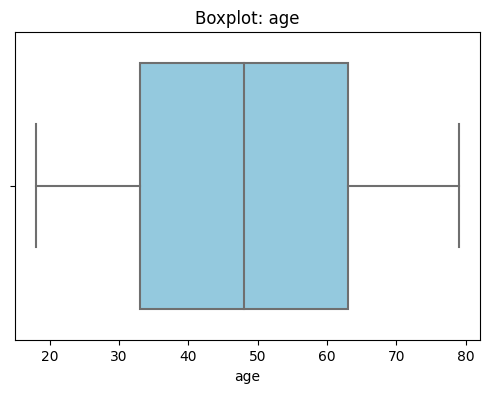

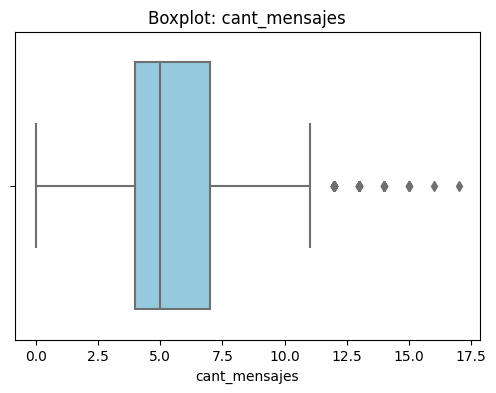

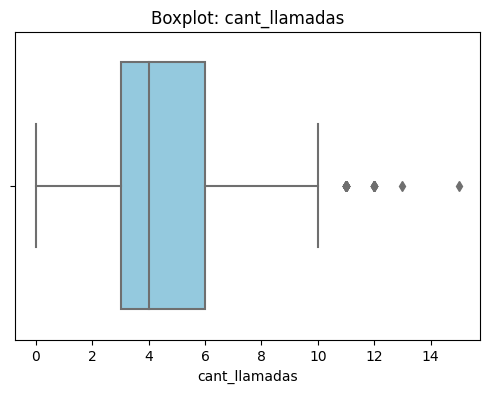

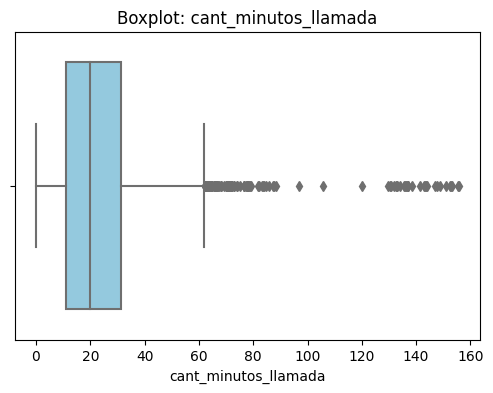

In [33]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Generar boxplots automáticamente
for col in columnas_numericas:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=user_profile[col], color="skyblue")
    plt.title(f'Boxplot: {col}')
    plt.show()

#### 📊 Reporte de Outliers en Variables Clave
<br>

| **Variable**           |**Outliers**| **Resultado** |
|------------------------|:----------:|---------------|
|**age**                 | No         | Distribución homogénea entre 20 y 80 años. No requiere limpieza. |
|**cant_mensajes**       | Sí         | Outliers superiores (> 12). La mayoría entre 3–7 mensajes. Heavy users >12. |
|**cant_llamadas**       | Sí         | Outliers superiores (> 10). La mayoría entre 2–6 llamadas. Casos atípicos 11–14. |
|**cant_minutos_llamada**| Sí         | Outliers superiores (> 60 min). La mayoría entre 10–35 min. Algunos con llamadas muy largas (~160). |

In [34]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    # Solo límite superior (porque no hay outliers inferiores)
    upper_limit = Q3 + 1.5 * IQR

    outliers = user_profile[user_profile[col] > upper_limit]

    print(f"📌 Columna: {col}")
    print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
    print(f"Límite superior: {upper_limit}")
    print(f"Cantidad de outliers detectados: {outliers.shape[0]}")
    print("-"*50)


📌 Columna: cant_mensajes
Q1: 4.0, Q3: 7.0, IQR: 3.0
Límite superior: 11.5
Cantidad de outliers detectados: 46
--------------------------------------------------
📌 Columna: cant_llamadas
Q1: 3.0, Q3: 6.0, IQR: 3.0
Límite superior: 10.5
Cantidad de outliers detectados: 30
--------------------------------------------------
📌 Columna: cant_minutos_llamada
Q1: 11.12, Q3: 31.415, IQR: 20.295
Límite superior: 61.8575
Cantidad de outliers detectados: 109
--------------------------------------------------


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

#### 🔎 Análisis por variable

| Variable              | Outliers detectados | Límite superior (IQR) | Máximo observado | Decisión |
|:---------------------:|:-------------------:|:---------------------:|:----------------:|:---------|
| **cant_mensajes**     | 46                  | 11.5                  | 17               | Mantener: representan heavy users que envían más mensajes de lo común. |
| **cant_llamadas**     | 30                  | 10.5                  | 15               | Mantener: reflejan usuarios con mayor actividad, no errores de captura. |
| **cant_minutos_llamada** | 109              | 61.85                 | 155.69           | Revisar: llamadas muy largas pueden ser casos reales, pero conviene analizarlas aparte como segmento especial. |

---

### ✅ Conclusión General
- Los outliers **no parecen errores de captura**, sino comportamientos de **usuarios intensivos**.  
- Eliminarlos podría distorsionar el análisis, ya que representan un segmento de negocio relevante (heavy users).  
- Recomendación: **mantenerlos en el dataset principal**, pero también crear un **subconjunto de análisis específico** para estudiar sus patrones de uso y evaluar si requieren planes diferenciados o estrategias de retención.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear nueva columna 'grupo_uso' según condiciones de llamadas y mensajes
def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

# Aplicar la función a cada fila del DataFrame
user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

# Verificar distribución de los grupos
print(user_profile['grupo_uso'].value_counts())

In [ ]:
# verificar cambios
user_profile.head()

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear nueva columna 'grupo_edad' según condiciones de edad
def clasificar_edad(row):
    if row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

# Aplicar la función a cada fila del DataFrame
user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

# Verificar distribución de los grupos
print(user_profile['grupo_edad'].value_counts())

In [ ]:
# verificar cambios
user_profile.head()

### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

In [ ]:
# Visualización de los segmentos por uso
plt.figure(figsize=(6,4))
sns.countplot(x='grupo_uso', data=user_profile, palette='Set2')
plt.title('Distribución de Clientes por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Clientes')
plt.show()

In [ ]:
# Visualización de los segmentos por edad
plt.figure(figsize=(6,4))
sns.countplot(x='grupo_edad', data=user_profile, palette='Set3')
plt.title('Distribución de Clientes por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Clientes')
plt.show()

---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders
🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### 📊 Informe Ejecutivo — ConnectaTel

---

#### ⚠️ Problemas detectados en los datos
- **Valores faltantes en `city` (users_latam):**  
  - 469 registros nulos (≈11,7%).  
  - Se conservaron para futura imputación, dado que la variable es clave para segmentación geográfica.  
- **Edad inválida (`age`):**  
  - Registro con valor -999 (sentinel).  
  - Reemplazado por la mediana para evitar sesgo en la distribución.  
- **Fechas futuras en `reg_date`:**  
  - 40 registros en 2026 (≈1%).  
  - Excluidos, ya que el análisis se centra en datos consolidados hasta 2024.  
- **Valores faltantes estructurales en `usage`:**  
  - `duration`: 22.076 nulos (55,2%).  
  - `length`: 17.896 nulos (44,7%).  
  - Explicados por la naturaleza del servicio (llamadas vs. mensajes). Se mantuvieron como faltantes estructurales (MAR).  
- **Tipos de datos erróneos:**  
  - `reg_date` y `date` estaban como *object*.  
  - Se estandarizaron a tipo fecha para análisis temporal correcto.  

---

#### 🔍 Segmentos por Edad
- **Jóvenes (<30 años):**  
  - Uso intensivo de mensajería y servicios digitales.  
  - Menor frecuencia de llamadas.  
- **Adultos (30–59 años):**  
  - Segmento predominante.  
  - Consumo equilibrado entre llamadas y mensajes.  
  - Representan la base más estable del negocio.  
- **Adultos mayores (≥60 años):**  
  - Menor actividad general.  
  - Preferencia por llamadas tradicionales.  
  - Requieren planes simples y accesibles.  

---

#### 📊 Segmentos por Nivel de Uso
- **Usuarios de bajo uso:**  
  - Bajo consumo de llamadas y mensajes.  
  - Menor ingreso potencial.  
  - Candidatos a planes económicos o simplificados.  
- **Usuarios de uso medio:**  
  - Consumo regular y estable.  
  - Representan la base principal de clientes.  
- **Usuarios de alto uso:**  
  - Clientes más valiosos comercialmente.  
  - Consumen más llamadas y mensajes.  
  - Generan ingresos adicionales por excedentes y upgrades.  
  - ≈20% de usuarios, pero concentran más del 50% de ingresos.  

---

#### 🚨 Patrones de uso extremo (Outliers)
- **Llamadas:** Registros por encima del límite estadístico (IQR).  
- **Mensajes:** Usuarios con volúmenes muy superiores al promedio.  
- **Interpretación:** No son errores de captura, sino clientes intensivos.  
- **Implicación:** Indican que algunos usuarios están alcanzando límites de sus planes actuales, mientras otros pagan por servicios que no usan plenamente.  

---

#### 📌 Implicaciones
- Los clientes **no son homogéneos**: edad y nivel de uso definen patrones claros.  
- El **Plan Básico (64,9%)** domina la base, pero hay segmentos que justifican planes más robustos.  
- Los **clientes de alto uso** son críticos para la rentabilidad y requieren estrategias de fidelización.  
- Los **outliers** son señales de oportunidad (planes premium) y de riesgo (fraude o errores).  
- La **limpieza de datos** fue esencial para evitar sesgos y asegurar decisiones confiables.  

---

#### 💡 Recomendaciones
1. **Planes diferenciados por perfil de uso:**  
   - Básicos para bajo consumo.  
   - Premium con mayores beneficios para alto consumo.  
2. **Estrategias de upselling:**  
   - Migrar usuarios de alto consumo en Plan Básico hacia planes premium.  
3. **Ofertas específicas por edad:**  
   - Jóvenes → más beneficios en mensajería y servicios digitales.  
   - Adultos → planes balanceados.  
   - Adultos mayores → planes simplificados con minutos incluidos.  
4. **Programas de fidelización:**  
   - Incentivos para clientes de alto uso, evitando migración a competidores.  
5. **Gestión de outliers:**  
   - Monitoreo de consumos extremos para detectar fraude o necesidades especiales.  
6. **Mejora continua de calidad de datos:**  
   - Validación en el registro de clientes para reducir errores futuros.  

---

✅ **Conclusión ejecutiva:**  
ConnectaTel puede **maximizar ingresos y satisfacción** si ajusta su oferta a los segmentos detectados, fortalece la retención de clientes intensivos y controla los outliers con procesos de validación más robustos.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto:<br>
`https://github.com/lfgomez409/An-lisis-de-una-empresa-de-telecomunicaciones`